In [ ]:
# ============================================================
# STAGE 2: TEMPORAL STRUCTURING & TRAINING STRATEGY:- Reduced feature training (15 features)
# Step 1: Load the Final Modelling Dataset
# ============================================================

# Import the required library
import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt

# Specify the path to the modelling dataset
file_path = "AirQuality_RFE_Model_Dataset.csv"

# Load the dataset
df = pd.read_csv(file_path)

# Display dataset information
print("Dataset loaded successfully.\n")
print(f"Dataset Shape: {df.shape}")

# Preview the first five observations
df.head()

Dataset loaded successfully.

Dataset Shape: (17519, 16)


,PM10,RH,WD,WD_cos,PM2.5_lag1,PM2.5_lag6,PM2.5_lag12,PM2.5_lag24,PM2.5_rollmean6,PM2.5_rollmean12,PM2.5_rollmean24,PM2.5_rollstd24,Temp_RH,PM2.5_RH,PM2.5_PM10_ratio,Target_PM2.5
0,162.973502,93.742130,246.205085,-0.403464,47.898415,46.952448,64.659620,65.119368,48.250298,50.100358,71.723232,29.702806,2692.019771,4356.730214,0.285173,49.260070
1,168.452719,95.791463,257.415000,-0.217888,46.475690,49.537279,56.190772,108.224682,48.204096,49.522799,69.266373,28.982209,2755.489340,4718.694156,0.292427,65.935270
2,221.879274,94.519977,285.770000,0.271776,49.260070,49.924200,54.798287,140.734862,50.872608,50.450881,66.149723,24.662506,2690.511141,6232.200157,0.297167,74.101551
3,245.929266,90.512215,294.951667,0.421854,65.935270,46.865442,53.681168,138.152391,55.411959,52.152580,63.480938,19.446036,2533.798955,6707.095576,0.301312,68.002704
4,217.713974,92.148372,292.106667,0.376332,74.101551,48.800760,51.907127,126.808911,58.612283,53.493878,61.030680,14.085662,2554.260737,6266.338463,0.312349,57.365491


In [2]:
# ============================================================
# Step 2: Separate Predictor Variables and Target Variable
# ============================================================

# Create the predictor matrix (X)
# Target_PM2.5 is excluded because it is the response variable.
X = df.drop(columns=["Target_PM2.5"])

# Define the target variable (y)
# This represents the one-hour-ahead PM2.5 concentration.
y = df["Target_PM2.5"]

# Display the dimensions
print(f"Predictor Matrix Shape : {X.shape}")
print(f"Target Vector Shape    : {y.shape}")

# Display the predictor variables
print("\nPredictor Variables:")
print(list(X.columns))

Predictor Matrix Shape : (17519, 15)
Target Vector Shape    : (17519,)

Predictor Variables:
['PM10', 'RH', 'WD', 'WD_cos', 'PM2.5_lag1', 'PM2.5_lag6', 'PM2.5_lag12', 'PM2.5_lag24', 'PM2.5_rollmean6', 'PM2.5_rollmean12', 'PM2.5_rollmean24', 'PM2.5_rollstd24', 'Temp_RH', 'PM2.5_RH', 'PM2.5_PM10_ratio']


In [3]:
# ============================================================
# Step 3: Chronological Train-Test Split
# ============================================================

# Since this is a time-series dataset, the observations
# are split chronologically. The first 80% of the data
# are used for training, while the remaining 20%
# are reserved for testing.

# Define the training proportion
train_ratio = 0.80

# Calculate the split index
split_index = int(len(df) * train_ratio)

# Split the predictor variables
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

# Split the target variable
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Display the sample sizes
print(f"Training Samples : {len(X_train)}")
print(f"Testing Samples  : {len(X_test)}")

Training Samples : 14015
Testing Samples  : 3504


In [4]:
# ============================================================
# Step 4: Time Series Cross-Validation
# ============================================================

from sklearn.model_selection import TimeSeriesSplit

# Configure an expanding-window cross-validation strategy.
# Each fold trains on earlier observations and validates
# on subsequent observations, preventing temporal leakage.
tscv = TimeSeriesSplit(n_splits=5)

# Display the size of each fold
for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):

    print("=" * 50)
    print(f"Fold {fold}")
    print("=" * 50)

    print(f"Training Samples  : {len(train_idx)}")
    print(f"Validation Samples: {len(val_idx)}")

    print(f"Training Index Range   : {train_idx[0]} - {train_idx[-1]}")
    print(f"Validation Index Range : {val_idx[0]} - {val_idx[-1]}")

Fold 1
Training Samples  : 2340
Validation Samples: 2335
Training Index Range   : 0 - 2339
Validation Index Range : 2340 - 4674
Fold 2
Training Samples  : 4675
Validation Samples: 2335
Training Index Range   : 0 - 4674
Validation Index Range : 4675 - 7009
Fold 3
Training Samples  : 7010
Validation Samples: 2335
Training Index Range   : 0 - 7009
Validation Index Range : 7010 - 9344
Fold 4
Training Samples  : 9345
Validation Samples: 2335
Training Index Range   : 0 - 9344
Validation Index Range : 9345 - 11679
Fold 5
Training Samples  : 11680
Validation Samples: 2335
Training Index Range   : 0 - 11679
Validation Index Range : 11680 - 14014


In [5]:
# ============================================================
# STAGE 2: MODEL-SPECIFIC DATA PREPARATION
# Step 1: Prepare Data for Tree-Based Models
# ============================================================

# Random Forest and XGBoost use the original predictor values.
# No feature scaling is required because tree-based algorithms
# are insensitive to differences in feature magnitude.

X_train_tree = X_train.copy()
X_test_tree = X_test.copy()

print("Tree-based model datasets prepared successfully.\n")

print(f"Training Shape : {X_train_tree.shape}")
print(f"Testing Shape  : {X_test_tree.shape}")

Tree-based model datasets prepared successfully.

Training Shape : (14015, 15)
Testing Shape  : (3504, 15)


In [6]:
# ============================================================
# Step 2: Standardize Features for CNN, LSTM and SVM
# ============================================================

from sklearn.preprocessing import StandardScaler

# Initialize the feature scaler
scaler = StandardScaler()

# Learn scaling parameters from the training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation to the testing data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully.\n")

print(f"Scaled Training Shape : {X_train_scaled.shape}")
print(f"Scaled Testing Shape  : {X_test_scaled.shape}")

Feature scaling completed successfully.

Scaled Training Shape : (14015, 15)
Scaled Testing Shape  : (3504, 15)


In [7]:
# ============================================================
# STAGE 3: RANDOM FOREST REGRESSION
# Step 1: Import Required Libraries
# ============================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

In [8]:
# ============================================================
# Step 2: Initialize the Random Forest Regressor
# ============================================================

from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest model
rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

print(rf)

RandomForestRegressor(n_jobs=-1, random_state=42)


In [9]:
# ============================================================
# Step 3: Define Hyperparameter Search Space
# ============================================================

# Hyperparameter combinations to evaluate
param_grid = {

    "n_estimators": [100, 200],

    "max_depth": [10, 20, None],

    "min_samples_split": [2, 5],

    "min_samples_leaf": [1, 2]
}

print(param_grid)

{'n_estimators': [100, 200], 'max_depth': [10, 20, None], 'min_samples_split': [2, 5], 'min_samples_leaf': [1, 2]}


In [10]:
# ============================================================
# Step 4: Hyperparameter Optimization
# ============================================================

# Configure Grid Search using the TimeSeriesSplit
# strategy established earlier.

grid_search = GridSearchCV(

    estimator=rf,

    param_grid=param_grid,

    cv=tscv,

    scoring="neg_root_mean_squared_error",

    n_jobs=-1,

    verbose=2
)

# Train the models
grid_search.fit(X_train_tree, y_train)

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Score:")
print(-grid_search.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits

Best Parameters:
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}

Best Cross-Validation Score:
4.448064245740848


In [11]:
# ============================================================
# Step 5: Retrieve the Best Random Forest Model
# ============================================================

# Extract the optimized model
best_rf = grid_search.best_estimator_

print("Optimized Random Forest Model:")
print(best_rf)

Optimized Random Forest Model:
RandomForestRegressor(max_depth=10, min_samples_leaf=2, min_samples_split=5,
                      n_estimators=200, n_jobs=-1, random_state=42)


In [12]:
# ============================================================
# Step 6: Predict PM2.5 Concentrations
# ============================================================

# Predict one-hour-ahead PM2.5 concentrations
y_pred_rf = best_rf.predict(X_test_tree)

print("Prediction completed successfully.")
print(f"Number of predictions: {len(y_pred_rf)}")

Prediction completed successfully.
Number of predictions: 3504


In [13]:
# ============================================================
# Step 7: Evaluate Model Performance
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred_rf)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2 = r2_score(y_test, y_pred_rf)

print("=" * 50)
print("Optimized Random Forest Performance")
print("=" * 50)

print(f"MAE  : {mae:.4f} µg/m³")
print(f"RMSE : {rmse:.4f} µg/m³")
print(f"R²   : {r2:.4f}")

Optimized Random Forest Performance
MAE  : 2.0948 µg/m³
RMSE : 3.3765 µg/m³
R²   : 0.7726


In [14]:
# ============================================================
# Step 8: Summary Table
# ============================================================

import pandas as pd

rf_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Value": [mae, rmse, r2]
})

rf_results

,Metric,Value
0,MAE,2.094774
1,RMSE,3.376501
2,R²,0.772624


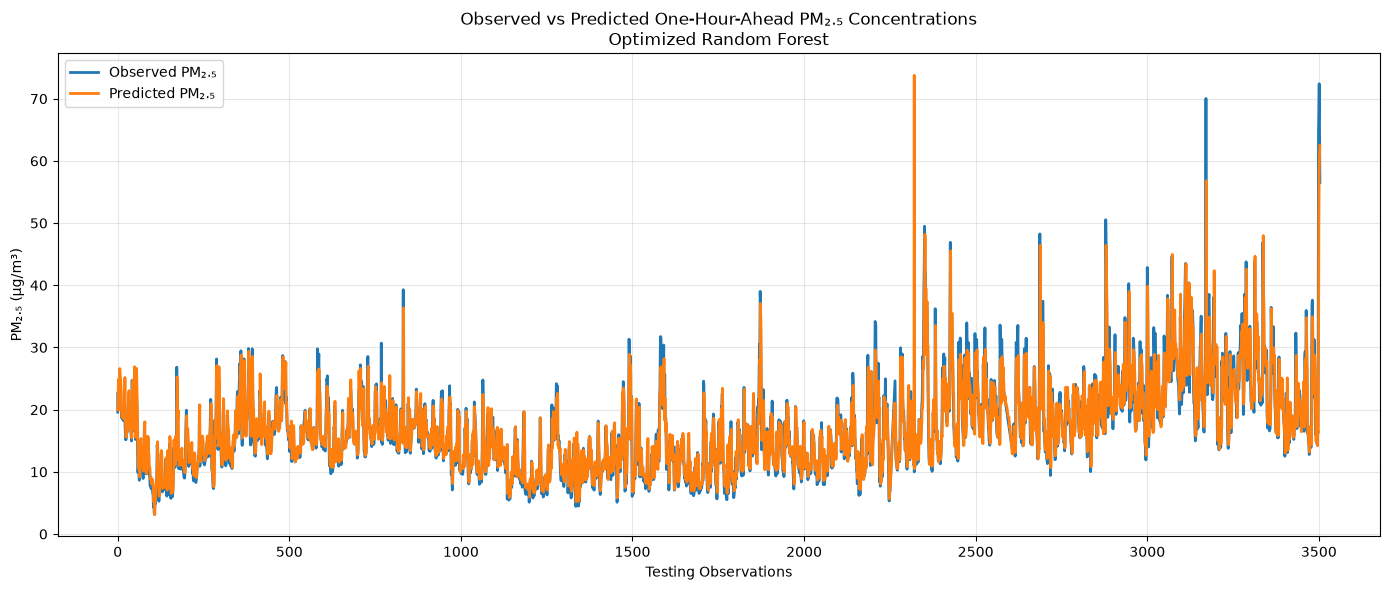

In [15]:
# ============================================================
# Figure 4.1: Actual vs Predicted PM2.5
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

plt.plot(
    y_test.values,
    label="Observed PM₂.₅",
    linewidth=2
)

plt.plot(
    y_pred_rf,
    label="Predicted PM₂.₅",
    linewidth=2
)

plt.title("Observed vs Predicted One-Hour-Ahead PM₂.₅ Concentrations\nOptimized Random Forest")

plt.xlabel("Testing Observations")

plt.ylabel("PM₂.₅ (µg/m³)")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

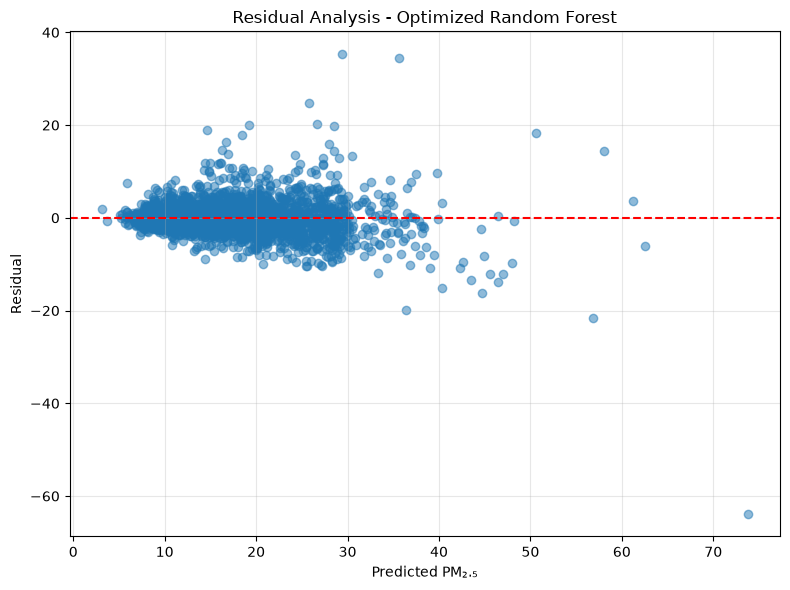

In [16]:
# ============================================================
# Figure 4.2: Residual Plot
# ============================================================

residuals = y_test.values - y_pred_rf

plt.figure(figsize=(8,6))

plt.scatter(
    y_pred_rf,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted PM₂.₅")

plt.ylabel("Residual")

plt.title("Residual Analysis - Optimized Random Forest")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

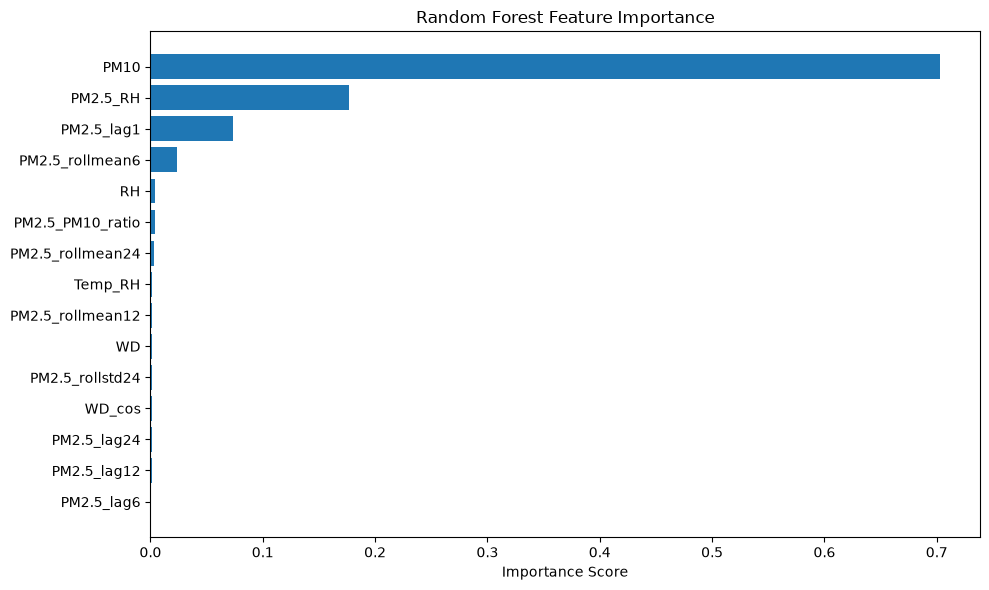

,Feature,Importance
0,PM10,0.703323
13,PM2.5_RH,0.176467
4,PM2.5_lag1,0.073721
8,PM2.5_rollmean6,0.023851
1,RH,0.004450
14,PM2.5_PM10_ratio,0.004062
10,PM2.5_rollmean24,0.002980
12,Temp_RH,0.001836
9,PM2.5_rollmean12,0.001792
2,WD,0.001773


In [17]:
# ============================================================
# Figure 4.3: Feature Importance
# ============================================================

feature_importance = pd.DataFrame({
    "Feature": X_train_tree.columns,
    "Importance": best_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10,6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance")

plt.xlabel("Importance Score")

plt.tight_layout()

plt.show()

feature_importance

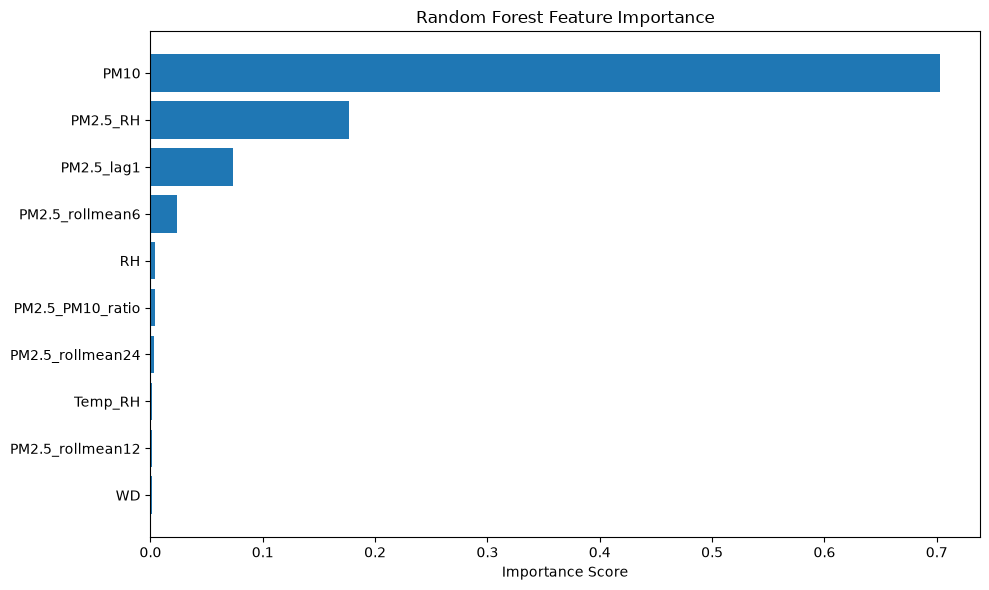

In [18]:
feature_importance_RF = (
    feature_importance
    .sort_values("Importance", ascending=False)
    .head(10)
)

plt.figure(figsize=(10,6))

plt.barh(
    feature_importance_RF["Feature"],
    feature_importance_RF["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance")

plt.xlabel("Importance Score")

plt.tight_layout()

plt.show()

In [19]:
# ============================================================
# Baseline Random Forest Regression
# ============================================================

from sklearn.ensemble import RandomForestRegressor

# Initialize baseline model
baseline_rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

# Train the model
baseline_rf.fit(X_train_tree, y_train)

print("Baseline Random Forest trained successfully.")

Baseline Random Forest trained successfully.


In [20]:
# ============================================================
# Baseline Predictions
# ============================================================

baseline_pred = baseline_rf.predict(X_test_tree)

print("Predictions completed.")

Predictions completed.


In [21]:
# ============================================================
# Baseline Model Evaluation
# ============================================================

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

print("="*55)
print("BASELINE RANDOM FOREST PERFORMANCE")
print("="*55)

print(f"MAE : {baseline_mae:.4f}")
print(f"RMSE: {baseline_rmse:.4f}")
print(f"R²  : {baseline_r2:.4f}")

BASELINE RANDOM FOREST PERFORMANCE
MAE : 2.1331
RMSE: 3.3971
R²  : 0.7698


In [22]:
comparison = pd.DataFrame({
    "Model": ["Baseline RF", "Optimized RF"],
    "MAE": [baseline_mae, mae],
    "RMSE": [baseline_rmse, rmse],
    "R²": [baseline_r2, r2]
})

comparison

,Model,MAE,RMSE,R²
0,Baseline RF,2.133072,3.397068,0.769846
1,Optimized RF,2.094774,3.376501,0.772624


In [23]:
!pip install xgboost

In [24]:
# ============================================================
# Import XGBoost
# ============================================================

from xgboost import XGBRegressor

print("XGBoost imported successfully.")


# ============================================================
# Initialize XGBoost Regressor
# ============================================================

xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

print(xgb)

XGBoost imported successfully.
XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=-1, num_parallel_tree=None, ...)


In [25]:
# ============================================================
# Hyperparameter Grid
# ============================================================

xgb_param_grid = {

    "n_estimators": [100, 200],

    "max_depth": [4, 6, 8],

    "learning_rate": [0.05, 0.1],

    "subsample": [0.8, 1.0],

    "colsample_bytree": [0.8, 1.0]

}

print("Total combinations:",
      2*3*2*2*2)

Total combinations: 48


In [26]:
# ============================================================
# Hyperparameter Optimization
# ============================================================

xgb_grid = GridSearchCV(

    estimator=xgb,

    param_grid=xgb_param_grid,

    cv=tscv,

    scoring="neg_root_mean_squared_error",

    n_jobs=-1,

    verbose=2

)

xgb_grid.fit(X_train_tree, y_train)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.05, 0.1], 'max_depth': [4, 6, ...], 'n_estimators': [100, 200], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",TimeSeriesSpl...est_size=None)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about mu

In [27]:
# ============================================================
# Best XGBoost Hyperparameters
# ============================================================

print("=" * 60)
print("BEST XGBOOST HYPERPARAMETERS")
print("=" * 60)

print(xgb_grid.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-xgb_grid.best_score_)

BEST XGBOOST HYPERPARAMETERS
{'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 200, 'subsample': 0.8}

Best Cross-Validation RMSE:
4.162927814834699


In [28]:
# ============================================================
# Generate Predictions
# ============================================================

best_xgb = xgb_grid.best_estimator_
y_pred_xgb = best_xgb.predict(X_test_tree)

print("Predictions completed successfully.")


# ============================================================
# Evaluate XGBoost Regression
# ============================================================

xgb_mae = mean_absolute_error(y_test, y_pred_xgb)
xgb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
xgb_r2 = r2_score(y_test, y_pred_xgb)

print("=" * 55)
print("XGBOOST REGRESSION PERFORMANCE")
print("=" * 55)

print(f"MAE : {xgb_mae:.4f}")
print(f"RMSE: {xgb_rmse:.4f}")
print(f"R²  : {xgb_r2:.4f}")

Predictions completed successfully.
XGBOOST REGRESSION PERFORMANCE
MAE : 2.1663
RMSE: 3.3313
R²  : 0.7787


In [29]:
# ============================================================
# Baseline XGBoost Regression
# ============================================================

baseline_xgb = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

baseline_xgb.fit(X_train_tree, y_train)

print("Baseline XGBoost trained successfully.")

# ============================================================
# Baseline Predictions
# ============================================================

baseline_xgb_pred = baseline_xgb.predict(X_test_tree)

print("Predictions completed.")

# ============================================================
# Baseline Model Evaluation
# ============================================================

baseline_xgb_mae = mean_absolute_error(y_test, baseline_xgb_pred)
baseline_xgb_rmse = np.sqrt(mean_squared_error(y_test, baseline_xgb_pred))
baseline_xgb_r2 = r2_score(y_test, baseline_xgb_pred)

print("="*55)
print("BASELINE XGBOOST PERFORMANCE")
print("="*55)

print(f"MAE : {baseline_xgb_mae:.4f}")
print(f"RMSE: {baseline_xgb_rmse:.4f}")
print(f"R²  : {baseline_xgb_r2:.4f}")

Baseline XGBoost trained successfully.
Predictions completed.
BASELINE XGBOOST PERFORMANCE
MAE : 2.2132
RMSE: 3.4227
R²  : 0.7664


In [30]:
# ============================================================
# Baseline vs Optimized Comparison
# ============================================================

xgb_comparison = pd.DataFrame({
    "Model": ["Baseline XGBoost", "Optimized XGBoost"],
    "MAE": [baseline_xgb_mae, xgb_mae],
    "RMSE": [baseline_xgb_rmse, xgb_rmse],
    "R²": [baseline_xgb_r2, xgb_r2]
})

xgb_comparison

,Model,MAE,RMSE,R²
0,Baseline XGBoost,2.213238,3.422741,0.766354
1,Optimized XGBoost,2.166254,3.331293,0.778672


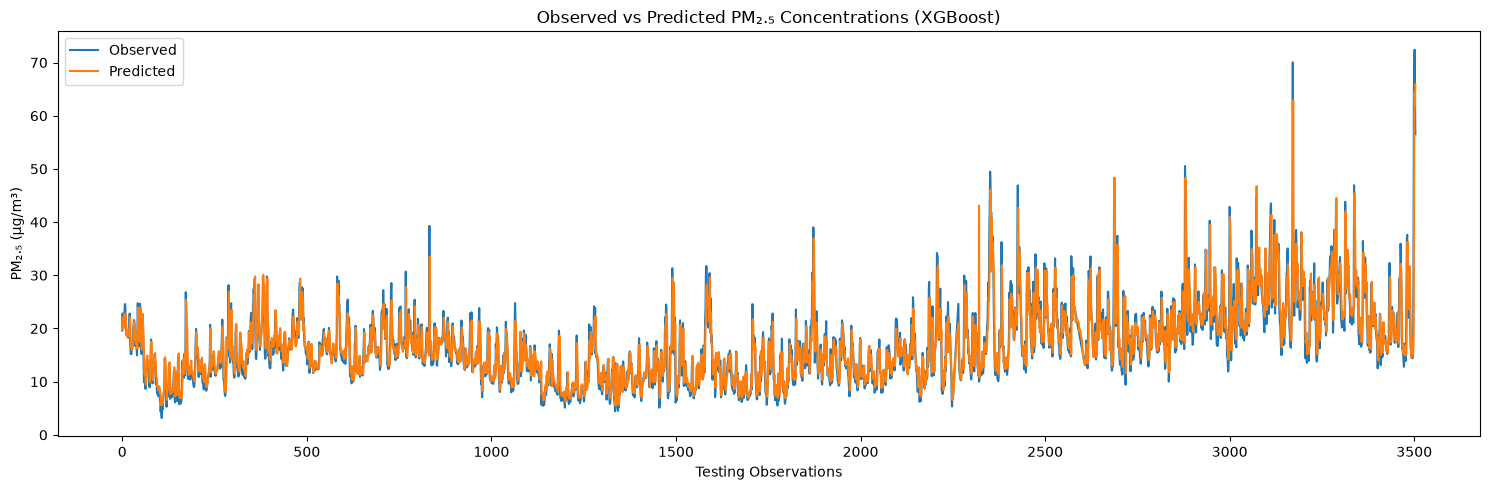

In [31]:
# ============================================================
# Actual vs Predicted Plot
# ============================================================

plt.figure(figsize=(15,5))

plt.plot(
    y_test.values,
    label="Observed",
    linewidth=1.5
)

plt.plot(
    y_pred_xgb,
    label="Predicted",
    linewidth=1.5
)

plt.title("Observed vs Predicted PM₂.₅ Concentrations (XGBoost)")
plt.xlabel("Testing Observations")
plt.ylabel("PM₂.₅ (µg/m³)")
plt.legend()

plt.tight_layout()
plt.show()

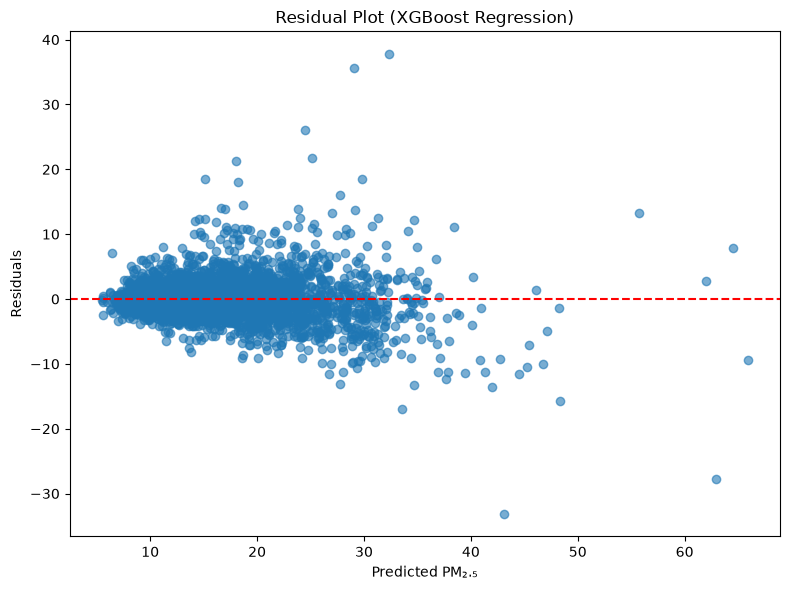

In [32]:
# ============================================================
# Residual Analysis
# ============================================================

xgb_residuals = y_test.values - y_pred_xgb

plt.figure(figsize=(8,6))

plt.scatter(
    y_pred_xgb,
    xgb_residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted PM₂.₅")
plt.ylabel("Residuals")
plt.title("Residual Plot (XGBoost Regression)")

plt.tight_layout()
plt.show()

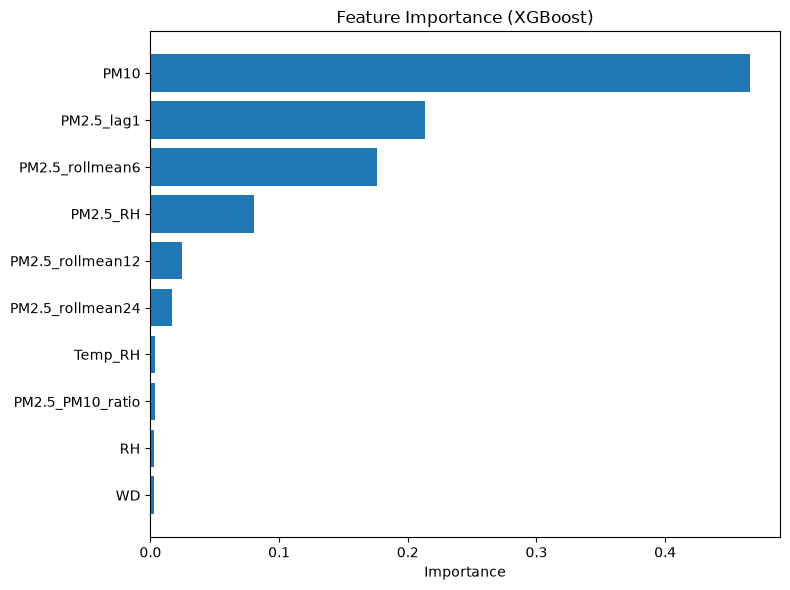

,Feature,Importance
0,PM10,0.465959
4,PM2.5_lag1,0.213316
8,PM2.5_rollmean6,0.175992
13,PM2.5_RH,0.080888
9,PM2.5_rollmean12,0.024877
10,PM2.5_rollmean24,0.016930
12,Temp_RH,0.003483
14,PM2.5_PM10_ratio,0.003306
1,RH,0.003150
2,WD,0.002545


In [33]:
# ============================================================
# Feature Importance
# ============================================================

xgb_importance = pd.DataFrame({
    "Feature": X_train_tree.columns,
    "Importance": best_xgb.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
).head(10)

plt.figure(figsize=(8,6))

plt.barh(
    xgb_importance["Feature"],
    xgb_importance["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Feature Importance (XGBoost)")
plt.xlabel("Importance")

plt.tight_layout()
plt.show()

xgb_importance

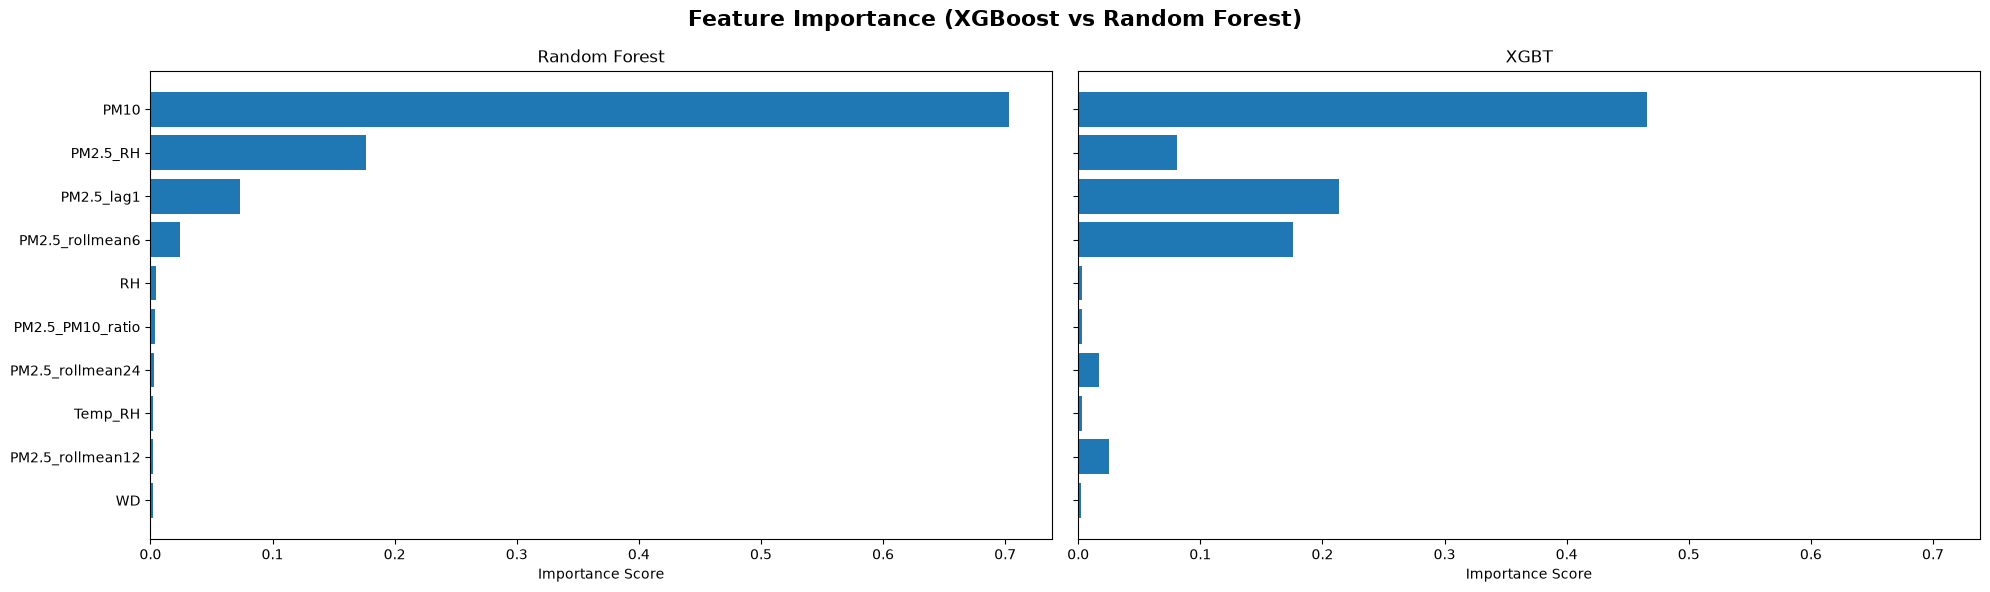

In [36]:
# Create a figure with three subplots.

fig, axes = plt.subplots(1, 2, figsize=(20, 6), sharex=True, sharey=True)

# ----------------------------------------------------
# RF
# ----------------------------------------------------
axes[0].barh(
    feature_importance_RF["Feature"],
    feature_importance_RF["Importance"]
)


axes[0].set_title("Random Forest")
axes[0].set_xlabel("Importance Score")

# ----------------------------------------------------
# XGBT
# ----------------------------------------------------
axes[1].barh(
    xgb_importance["Feature"],
    xgb_importance["Importance"]
)


axes[1].set_title("XGBT")
axes[1].set_xlabel("Importance Score")
#axes[1]. set_ylabel("Residual PM2.5 (µg/m³)")

# ----------------------------------------------------
# Figure title
# ----------------------------------------------------
fig.suptitle(
    "Feature Importance (XGBoost vs Random Forest)",
    fontsize=16,
    fontweight="bold"
)

plt.gca().invert_yaxis()

plt.tight_layout()
plt.savefig("features_importance.png")
plt.show()

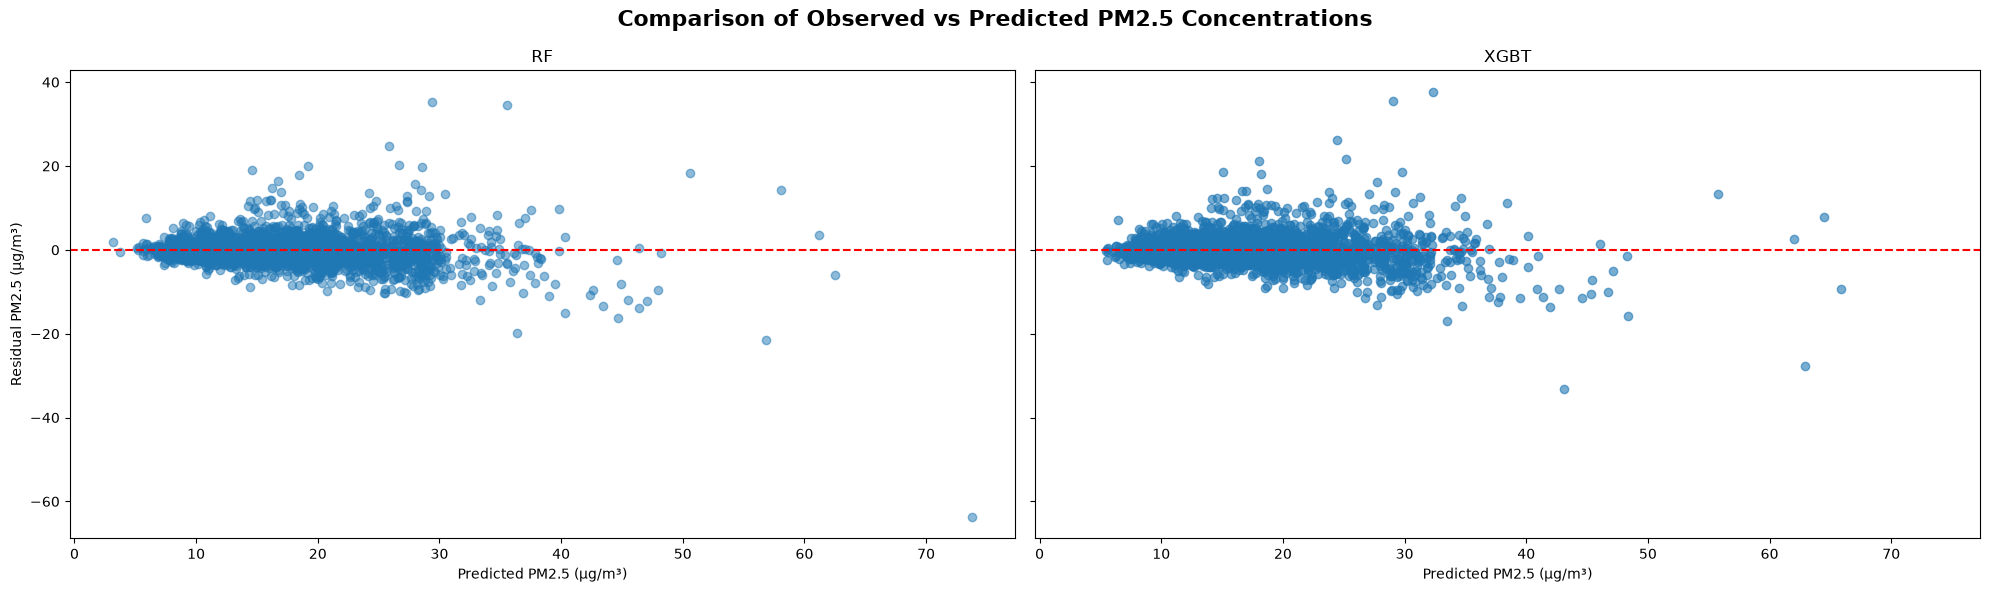

In [37]:
# Create a figure with three subplots.

fig, axes = plt.subplots(1, 2, figsize=(20, 6), sharex=True, sharey=True)

# ----------------------------------------------------
# RF
# ----------------------------------------------------
axes[0].scatter(
    y_pred_rf,
    residuals,
    alpha=0.5
)

axes[0].axhline(
    y=0,
    color="red",
    linestyle="--"
)

axes[0].set_title("RF")
axes[0].set_xlabel("Predicted PM2.5 (µg/m³)")
axes[0].set_ylabel("Residual PM2.5 (µg/m³)")

# ----------------------------------------------------
# XGBT
# ----------------------------------------------------
axes[1].scatter(
    y_pred_xgb,
    xgb_residuals,
    alpha=0.6
)

axes[1].axhline(
    y=0,
    color="red",
    linestyle="--"
)

axes[1].set_title("XGBT")
axes[1].set_xlabel("Predicted PM2.5 (µg/m³)")
#axes[1]. set_ylabel("Residual PM2.5 (µg/m³)")

# ----------------------------------------------------
# Figure title
# ----------------------------------------------------
fig.suptitle(
    "Comparison of Observed vs Predicted PM2.5 Concentrations",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("residua.png")
plt.show()

In [38]:
# ============================================================
# Sequence Length
# ============================================================

LOOKBACK = 24

# ============================================================
# Function to Create Time-Series Sequences
# ============================================================

import numpy as np

def create_sequences(X, y, lookback):

    X_seq = []
    y_seq = []

    for i in range(len(X) - lookback):

        X_seq.append(X[i:i + lookback])

        y_seq.append(y[i + lookback])

    return np.array(X_seq), np.array(y_seq)

# Create Training Sequences
X_train_seq, y_train_seq = create_sequences(
    X_train_scaled,
    y_train.values,
    LOOKBACK
)

X_test_seq, y_test_seq = create_sequences(
    X_test_scaled,
    y_test.values,
    LOOKBACK
)

#Print the Shape
print("Training Shape:", X_train_seq.shape)

print("Testing Shape :", X_test_seq.shape)

Training Shape: (13991, 24, 15)
Testing Shape : (3480, 24, 15)


# Convolutional Neural Network (1D-CNN) Regression



In [39]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [40]:
# ============================================================
# Import Deep Learning Libraries
# ============================================================

import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Conv1D,
    MaxPooling1D,
    Flatten,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import EarlyStopping

print(tf.__version__)

2.21.0


In [41]:
# ============================================================
# Build CNN Regression Model
# ============================================================

cnn_model = Sequential([

    Conv1D(
        filters=64,
        kernel_size=3,
        activation="relu",
        input_shape=(LOOKBACK, X_train_seq.shape[2])
    ),

    MaxPooling1D(pool_size=2),

    Dropout(0.2),

    Conv1D(
        filters=32,
        kernel_size=3,
        activation="relu"
    ),

    Flatten(),

    Dense(
        64,
        activation="relu"
    ),

    Dropout(0.2),

    Dense(1)

])

C:\Users\HP\anaconda3\envs\dl_env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [42]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 22, 64)              │           2,944 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 11, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 11, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 9, 32)               │           6,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 288)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 27,681 (108.13 KB)

 Trainable params: 27,681 (108.13 KB)

 Non-trainable params: 0 (0.00 B)

In [43]:
#Improve learning rate and stopping time
from tensorflow.keras.optimizers import Adam

cnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

In [44]:
# ============================================================
# Train the CNN Regression Model
# ============================================================

# Train the CNN using the sequential training data.
# The model learns from 80% of the training sequences while
# reserving 20% for validation to monitor generalization performance.

history_cnn = cnn_model.fit(

    # Input training sequences (24-hour look-back window)
    X_train_seq,

    # Corresponding target PM2.5 values
    y_train_seq,

    # Reserve 20% of the training data for validation
    validation_split=0.2,

    # Maximum number of training iterations
    epochs=100,

    # Number of samples processed before updating model weights
    batch_size=32,

    # Stop training early if validation loss does not improve
    callbacks=[early_stop],

    # Display training progress for each epoch
    verbose=1

)

Epoch 1/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - loss: 288.8657 - mae: 9.0855 - val_loss: 29.2231 - val_mae: 4.1752
Epoch 2/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - loss: 131.6812 - mae: 6.6029 - val_loss: 34.0223 - val_mae: 4.6167
Epoch 3/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 106.7891 - mae: 6.1512 - val_loss: 24.6555 - val_mae: 3.7966
Epoch 4/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 111.3862 - mae: 6.2113 - val_loss: 33.6108 - val_mae: 4.3485
Epoch 5/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 104.9471 - mae: 6.0581 - val_loss: 25.0858 - val_mae: 3.8978
Epoch 6/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 88.3459 - mae: 5.6359 - val_loss: 19.5110 - val_mae: 3.2694
Epoch 7/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 90.2176 - mae: 5.6375 - val_loss: 20.6624 - val_mae: 3.3785
Epoch 8/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - loss: 91.8588 - mae: 5.6544 - val_loss: 19.7282 - val_mae: 3.2799
Epoch 9/100
350/350

In [45]:
# ============================================================
# Improve Version
# Set Random Seed for Reproducibility
# ============================================================

import random
import numpy as np
import tensorflow as tf

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [46]:
# ============================================================
# Build CNN Regression Model
# ============================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv1D,
    MaxPooling1D,
    Flatten,
    Dense,
    Dropout
)

cnn_model = Sequential([

    # First convolutional layer
    Conv1D(
        filters=64,
        kernel_size=3,
        activation="relu",
        input_shape=(LOOKBACK, X_train_seq.shape[2])
    ),

    # Max pooling
    MaxPooling1D(pool_size=2),

    # Dropout
    Dropout(0.2),

    # Second convolutional layer
    Conv1D(
        filters=32,
        kernel_size=3,
        activation="relu"
    ),

    # Flatten feature maps
    Flatten(),

    # Fully connected layer
    Dense(
        64,
        activation="relu"
    ),

    # Dropout
    Dropout(0.2),

    # Output layer
    Dense(1)

])

cnn_model.summary()

C:\Users\HP\anaconda3\envs\dl_env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)                    │ (None, 22, 64)              │           2,944 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)       │ (None, 11, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 11, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_3 (Conv1D)                    │ (None, 9, 32)               │           6,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 288)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 27,681 (108.13 KB)

 Trainable params: 27,681 (108.13 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:
from tensorflow.keras.optimizers import Adam

cnn_model.compile(

    optimizer=Adam(learning_rate=0.001),

    loss="mse",

    metrics=["mae"]

)

In [48]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(

    monitor="val_loss",

    patience=15,

    restore_best_weights=True,

    mode="min",

    verbose=1

)

In [49]:
history_cnn = cnn_model.fit(

    X_train_seq,

    y_train_seq,

    validation_split=0.20,

    epochs=100,

    batch_size=32,

    callbacks=[early_stop],

    verbose=1

)

Epoch 1/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - loss: 238.6144 - mae: 8.2466 - val_loss: 26.5025 - val_mae: 3.8172
Epoch 2/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 117.4305 - mae: 6.3347 - val_loss: 23.9111 - val_mae: 3.6978
Epoch 3/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 102.7406 - mae: 6.0141 - val_loss: 22.6139 - val_mae: 3.6169
Epoch 4/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 92.8116 - mae: 5.8159 - val_loss: 20.6968 - val_mae: 3.3953
Epoch 5/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 92.2031 - mae: 5.7501 - val_loss: 21.8445 - val_mae: 3.5931
Epoch 6/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 91.8343 - mae: 5.6554 - val_loss: 19.0898 - val_mae: 3.2383
Epoch 7/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 85.1923 - mae: 5.5413 - val_loss: 17.8689 - val_mae: 3.1530
Epoch 8/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 85.1587 - mae: 5.5074 - val_loss: 17.5081 - val_mae: 3.0208
Epoch 9/100
350/350 ━

In [50]:
# ============================================================
# Generate Predictions Using the CNN Model
# ============================================================

# Predict PM2.5 concentrations for the testing dataset
cnn_predictions = cnn_model.predict(X_test_seq)

# Convert predictions from a 2D array to a 1D vector
cnn_predictions = cnn_predictions.flatten()

109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


In [51]:
# ============================================================
# Evaluate CNN Regression Performance
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

cnn_mae = mean_absolute_error(y_test_seq, cnn_predictions)

cnn_mse = mean_squared_error(y_test_seq, cnn_predictions)

cnn_rmse = np.sqrt(cnn_mse)

cnn_r2 = r2_score(y_test_seq, cnn_predictions)

print("=" * 50)
print("CNN Regression Performance")
print("=" * 50)

print(f"MAE  : {cnn_mae:.4f}")
print(f"MSE  : {cnn_mse:.4f}")
print(f"RMSE : {cnn_rmse:.4f}")
print(f"R²   : {cnn_r2:.4f}")

CNN Regression Performance
MAE  : 3.9924
MSE  : 32.9451
RMSE : 5.7398
R²   : 0.3460


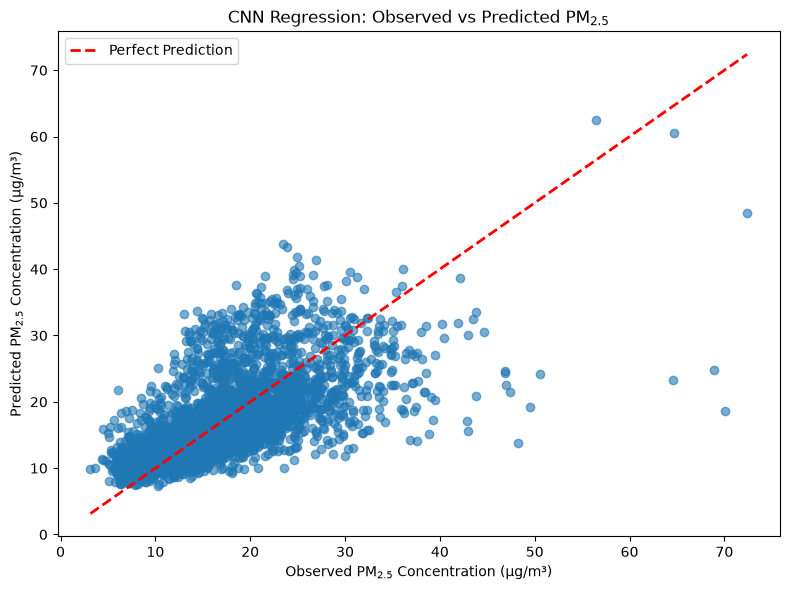

In [52]:
# ============================================================
# Observed vs Predicted Values (CNN)
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_seq,
    cnn_predictions,
    alpha=0.6
)

plt.plot(
    [y_test_seq.min(), y_test_seq.max()],
    [y_test_seq.min(), y_test_seq.max()],
    'r--',
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Observed PM$_{2.5}$ Concentration (µg/m³)")
plt.ylabel("Predicted PM$_{2.5}$ Concentration (µg/m³)")
plt.title("CNN Regression: Observed vs Predicted PM$_{2.5}$")
plt.legend()

plt.tight_layout()
plt.show()

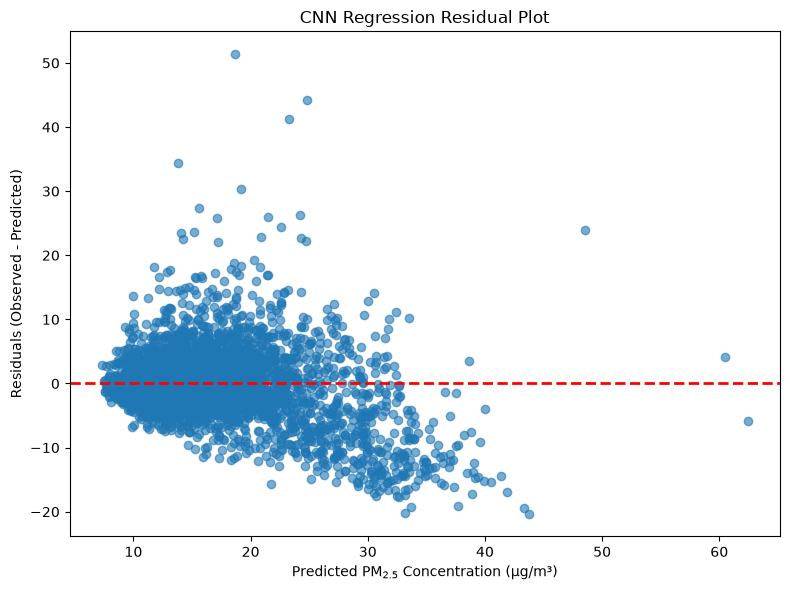

In [53]:
# ============================================================
# Residual Analysis (CNN)
# ============================================================

import matplotlib.pyplot as plt

# Calculate residuals
cnn_residuals = y_test_seq - cnn_predictions

plt.figure(figsize=(8,6))

plt.scatter(
    cnn_predictions,
    cnn_residuals,
    alpha=0.6
)

# Horizontal reference line
plt.axhline(
    y=0,
    color='red',
    linestyle='--',
    linewidth=2
)

plt.xlabel("Predicted PM$_{2.5}$ Concentration (µg/m³)")
plt.ylabel("Residuals (Observed - Predicted)")
plt.title("CNN Regression Residual Plot")

plt.tight_layout()
plt.show()

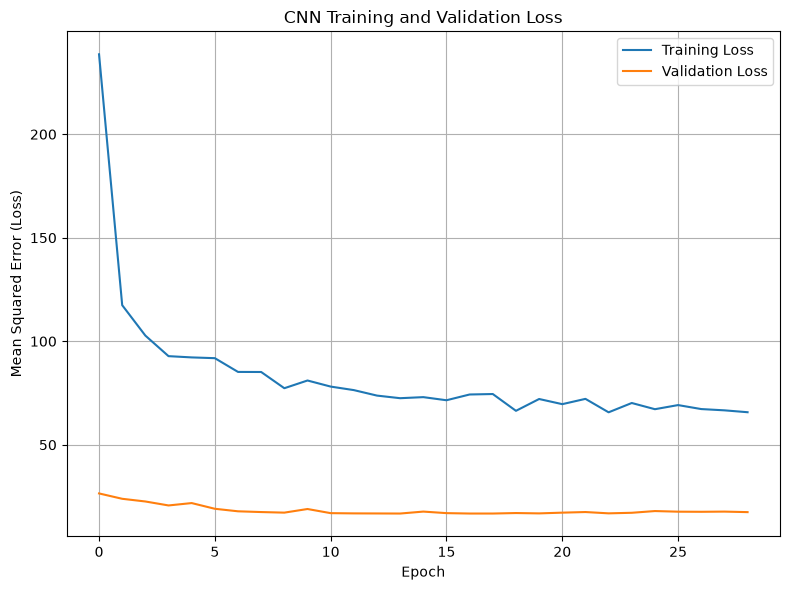

In [54]:
# ============================================================
# Training and Validation Loss Curves
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.plot(
    history_cnn.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_cnn.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Mean Squared Error (Loss)")

plt.title("CNN Training and Validation Loss")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# Long Short-Term Memory (LSTM) Model



In [55]:
# Import libraries
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [56]:
# Create a Sequential neural network model.
lstm_model = Sequential([

    # LSTM layer with 64 memory units to capture temporal dependencies
    # from the previous 24-hour observations.
    LSTM(
        units=64,
        input_shape=(LOOKBACK, X_train_seq.shape[2])
    ),

    # Dropout layer to reduce overfitting during training.
    Dropout(0.2),

    # Fully connected hidden layer with ReLU activation for
    # learning higher-level feature representations.
    Dense(
        32,
        activation="relu"
    ),

    # Output layer consisting of a single neuron for predicting
    # the one-hour-ahead PM2.5 concentration.
    Dense(1)

])

C:\Users\HP\anaconda3\envs\dl_env\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [57]:
# Display the architecture of the LSTM model.
lstm_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 64)                  │          20,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 22,593 (88.25 KB)

 Trainable params: 22,593 (88.25 KB)

 Non-trainable params: 0 (0.00 B)

In [58]:
# Compile the LSTM model using the Adam optimizer.
# Mean Squared Error (MSE) is used as the loss function,
# while Mean Absolute Error (MAE) is monitored as an
# additional performance metric during training.

lstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

In [59]:
# Configure EarlyStopping to prevent overfitting by monitoring
# the validation loss. Training stops if no improvement is
# observed for 15 consecutive epochs, and the model weights
# from the best-performing epoch are restored.

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

In [60]:
# Train the LSTM model using the sequential training dataset.
# Twenty percent of the training data is reserved for validation.
# EarlyStopping is used to terminate training when validation
# performance no longer improves.

history_lstm = lstm_model.fit(
    X_train_seq,
    y_train_seq,
    validation_split=0.20,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - loss: 729.9633 - mae: 12.5078 - val_loss: 17.8601 - val_mae: 3.2256
Epoch 2/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - loss: 113.0135 - mae: 5.8003 - val_loss: 16.8944 - val_mae: 3.1874
Epoch 3/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - loss: 73.5642 - mae: 5.1600 - val_loss: 15.0534 - val_mae: 2.8657
Epoch 4/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - loss: 66.3305 - mae: 4.9046 - val_loss: 15.2050 - val_mae: 2.9075
Epoch 5/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - loss: 63.8924 - mae: 4.7851 - val_loss: 15.1820 - val_mae: 2.9017
Epoch 6/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - loss: 63.5205 - mae: 4.7266 - val_loss: 15.0638 - val_mae: 2.8743
Epoch 7/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - loss: 58.7534 - mae: 4.5897 - val_loss: 15.5337 - val_mae: 2.9257
Epoch 8/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - loss: 55.8578 - mae: 4.5138 - val_loss: 15.2907 - val_mae: 2.8795
Epoch 9/100
350/350 

In [61]:
# Generate predictions for the testing dataset using the trained LSTM model.
lstm_predictions = lstm_model.predict(X_test_seq)

# Convert the predictions from a two-dimensional array to a one-dimensional array
# for compatibility with the evaluation metrics.
lstm_predictions = lstm_predictions.flatten()


# Import regression evaluation metrics.
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate the evaluation metrics.
lstm_mae = mean_absolute_error(y_test_seq, lstm_predictions)
lstm_mse = mean_squared_error(y_test_seq, lstm_predictions)
lstm_rmse = np.sqrt(lstm_mse)
lstm_r2 = r2_score(y_test_seq, lstm_predictions)

# Display the regression performance.
print("=" * 50)
print("LSTM Regression Performance")
print("=" * 50)
print(f"MAE  : {lstm_mae:.4f}")
print(f"MSE  : {lstm_mse:.4f}")
print(f"RMSE : {lstm_rmse:.4f}")
print(f"R²   : {lstm_r2:.4f}")

109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step
LSTM Regression Performance
MAE  : 5.1159
MSE  : 63.5779
RMSE : 7.9736
R²   : -0.2622


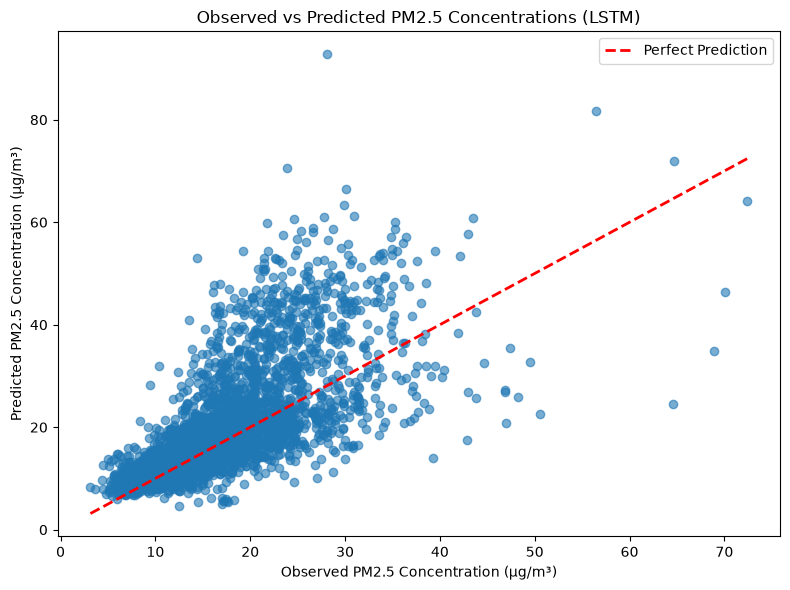

In [62]:
# Plot the observed versus predicted PM2.5 concentrations.

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_seq,
    lstm_predictions,
    alpha=0.6
)

# Plot the perfect prediction reference line.
plt.plot(
    [y_test_seq.min(), y_test_seq.max()],
    [y_test_seq.min(), y_test_seq.max()],
    "r--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Observed PM2.5 Concentration (µg/m³)")
plt.ylabel("Predicted PM2.5 Concentration (µg/m³)")
plt.title("Observed vs Predicted PM2.5 Concentrations (LSTM)")
plt.legend()

plt.tight_layout()
plt.show()

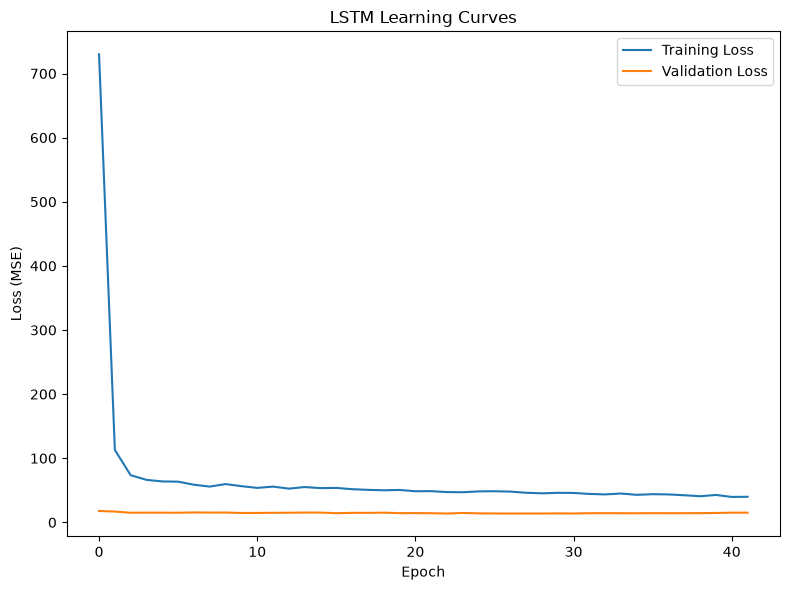

In [63]:
# Plot the training and validation loss curves.

plt.figure(figsize=(8, 6))

plt.plot(
    history_lstm.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_lstm.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("LSTM Learning Curves")

plt.legend()

plt.tight_layout()
plt.show()

# Hybrid XGBoost–LSTM Model



In [64]:
# Import the XGBoost regressor.
from xgboost import XGBRegressor

# Create the XGBoost feature extraction model.
xgb_feature_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42
)

# Train the XGBoost model using the training data.
xgb_feature_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [65]:
# Transform the training and testing datasets into XGBoost leaf-index features.

X_train_xgb = xgb_feature_model.apply(X_train)
X_test_xgb = xgb_feature_model.apply(X_test)

print("Training feature shape:", X_train_xgb.shape)
print("Testing feature shape:", X_test_xgb.shape)

Training feature shape: (14015, 100)
Testing feature shape: (3504, 100)


In [66]:
from sklearn.preprocessing import StandardScaler

# Create the scaler.
hybrid_scaler = StandardScaler()

# Fit the scaler on the training data and transform both datasets.
X_train_xgb_scaled = hybrid_scaler.fit_transform(X_train_xgb)
X_test_xgb_scaled = hybrid_scaler.transform(X_test_xgb)

In [67]:
# Generate sequential datasets from the transformed XGBoost features.

X_train_hybrid, y_train_hybrid = create_sequences(
    X_train_xgb_scaled,
    y_train.values,
    LOOKBACK
)

X_test_hybrid, y_test_hybrid = create_sequences(
    X_test_xgb_scaled,
    y_test.values,
    LOOKBACK
)

print("Training sequence shape:", X_train_hybrid.shape)
print("Testing sequence shape:", X_test_hybrid.shape)

Training sequence shape: (13991, 24, 100)
Testing sequence shape: (3480, 24, 100)


In [68]:
# Create the Hybrid XGBoost–LSTM model.
hybrid_model = Sequential([

    # LSTM layer for learning temporal relationships from
    # the XGBoost-transformed feature sequences.
    LSTM(
        units=64,
        input_shape=(LOOKBACK, X_train_hybrid.shape[2])
    ),

    # Dropout layer to reduce overfitting.
    Dropout(0.2),

    # Fully connected hidden layer.
    Dense(
        32,
        activation="relu"
    ),

    # Output layer for one-hour-ahead PM2.5 prediction.
    Dense(1)

])

C:\Users\HP\anaconda3\envs\dl_env\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [69]:
# Display the Hybrid XGBoost–LSTM architecture.
hybrid_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                        │ (None, 64)                  │          42,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 44,353 (173.25 KB)

 Trainable params: 44,353 (173.25 KB)

 Non-trainable params: 0 (0.00 B)

In [70]:
# Compile the Hybrid XGBoost–LSTM model using the Adam optimizer.
# Mean Squared Error (MSE) is used as the loss function,
# while Mean Absolute Error (MAE) is monitored as an
# additional performance metric.

hybrid_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)


# Configure EarlyStopping to monitor the validation loss.
# Training stops if the validation loss does not improve
# for 15 consecutive epochs, and the best model weights
# are automatically restored.

early_stop_hybrid = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

# Train the Hybrid XGBoost–LSTM model.

history_hybrid = hybrid_model.fit(
    X_train_hybrid,
    y_train_hybrid,
    validation_split=0.20,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop_hybrid],
    verbose=1
)

Epoch 1/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - loss: 746.6549 - mae: 11.9591 - val_loss: 15.3580 - val_mae: 2.8289
Epoch 2/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - loss: 132.2359 - mae: 6.2172 - val_loss: 17.4541 - val_mae: 3.1481
Epoch 3/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - loss: 80.3142 - mae: 5.4941 - val_loss: 16.6869 - val_mae: 3.0336
Epoch 4/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - loss: 70.4563 - mae: 5.1441 - val_loss: 16.2995 - val_mae: 3.0004
Epoch 5/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - loss: 64.3015 - mae: 4.8984 - val_loss: 16.5760 - val_mae: 2.9946
Epoch 6/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - loss: 59.3057 - mae: 4.6943 - val_loss: 16.9466 - val_mae: 3.0074
Epoch 7/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - loss: 56.4225 - mae: 4.5835 - val_loss: 16.9638 - val_mae: 3.0513
Epoch 8/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - loss: 54.6717 - mae: 4.5572 - val_loss: 18.0553 - val_mae: 3.1430
Epoch 9/100
350/350

### Hybrid Model Training Performance

The Hybrid XGBoost–LSTM model was trained for a maximum of 100 epochs using the Adam optimizer with EarlyStopping configured to monitor the validation loss. Training terminated automatically after **21 epochs**, with the model restoring the weights obtained at **Epoch 6**, where the lowest validation loss (**15.8095**) was achieved.

The training and validation losses decreased rapidly during the initial epochs, indicating that the model successfully learned meaningful patterns from the XGBoost-transformed sequential features. After the sixth epoch, the validation loss gradually increased while the training loss continued to decrease, suggesting the onset of overfitting. Consequently, the EarlyStopping mechanism prevented unnecessary training and restored the best-performing model parameters.

Overall, the hybrid model exhibited stable convergence and effective optimization, providing a suitable basis for evaluating whether the integration of XGBoost feature extraction with LSTM improves PM₂.₅ forecasting performance on the independent testing dataset.

In [71]:
# Generate predictions for the testing dataset.
hybrid_predictions = hybrid_model.predict(X_test_hybrid)

# Convert predictions to a one-dimensional array.
hybrid_predictions = hybrid_predictions.flatten()


# Calculate the regression evaluation metrics.

hybrid_mae = mean_absolute_error(y_test_hybrid, hybrid_predictions)
hybrid_mse = mean_squared_error(y_test_hybrid, hybrid_predictions)
hybrid_rmse = np.sqrt(hybrid_mse)
hybrid_r2 = r2_score(y_test_hybrid, hybrid_predictions)

print("=" * 50)
print("Hybrid XGBoost–LSTM Regression Performance")
print("=" * 50)
print(f"MAE  : {hybrid_mae:.4f}")
print(f"MSE  : {hybrid_mse:.4f}")
print(f"RMSE : {hybrid_rmse:.4f}")
print(f"R²   : {hybrid_r2:.4f}")

109/109 ━━━━━━━━━━━━━━━━━━━━ 16s 92ms/step
Hybrid XGBoost–LSTM Regression Performance
MAE  : 3.4092
MSE  : 24.2979
RMSE : 4.9293
R²   : 0.5176


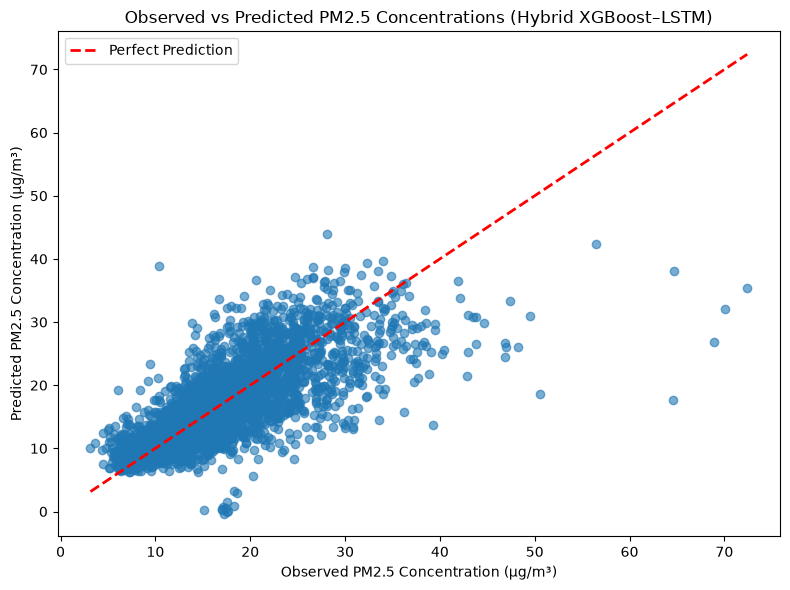

In [72]:
# Plot the observed versus predicted PM2.5 concentrations.

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_hybrid,
    hybrid_predictions,
    alpha=0.6
)

# Perfect prediction line
plt.plot(
    [y_test_hybrid.min(), y_test_hybrid.max()],
    [y_test_hybrid.min(), y_test_hybrid.max()],
    "r--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Observed PM2.5 Concentration (µg/m³)")
plt.ylabel("Predicted PM2.5 Concentration (µg/m³)")
plt.title("Observed vs Predicted PM2.5 Concentrations (Hybrid XGBoost–LSTM)")
plt.legend()

plt.tight_layout()
plt.show()

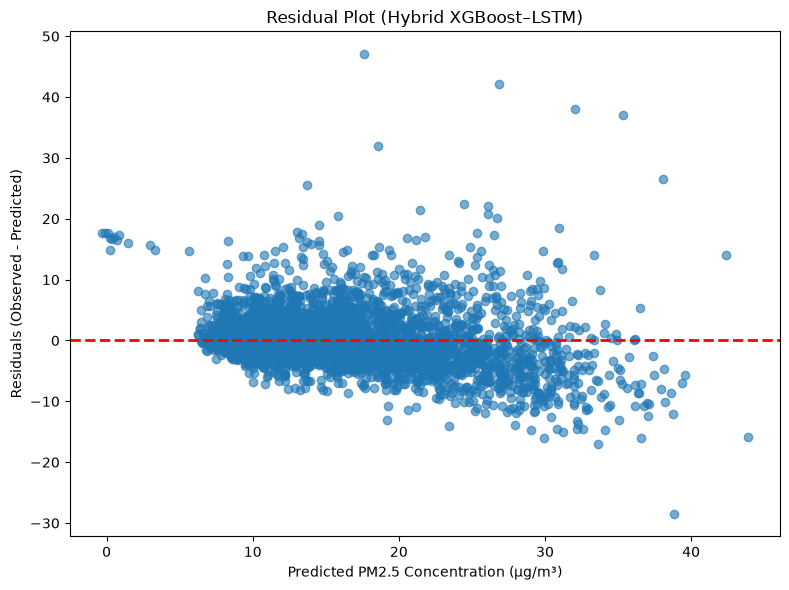

In [73]:
# Calculate the residuals.
hybrid_residuals = y_test_hybrid - hybrid_predictions

# Plot the residuals.

plt.figure(figsize=(8, 6))

plt.scatter(
    hybrid_predictions,
    hybrid_residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.xlabel("Predicted PM2.5 Concentration (µg/m³)")
plt.ylabel("Residuals (Observed - Predicted)")
plt.title("Residual Plot (Hybrid XGBoost–LSTM)")

plt.tight_layout()
plt.show()

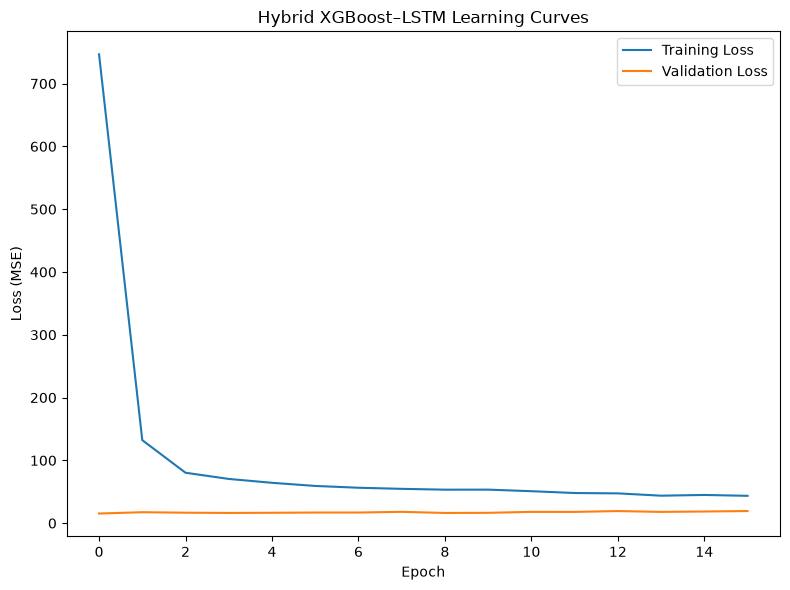

In [74]:
# Plot the training and validation loss.

plt.figure(figsize=(8, 6))

plt.plot(
    history_hybrid.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_hybrid.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("Hybrid XGBoost–LSTM Learning Curves")

plt.legend()

plt.tight_layout()
plt.show()

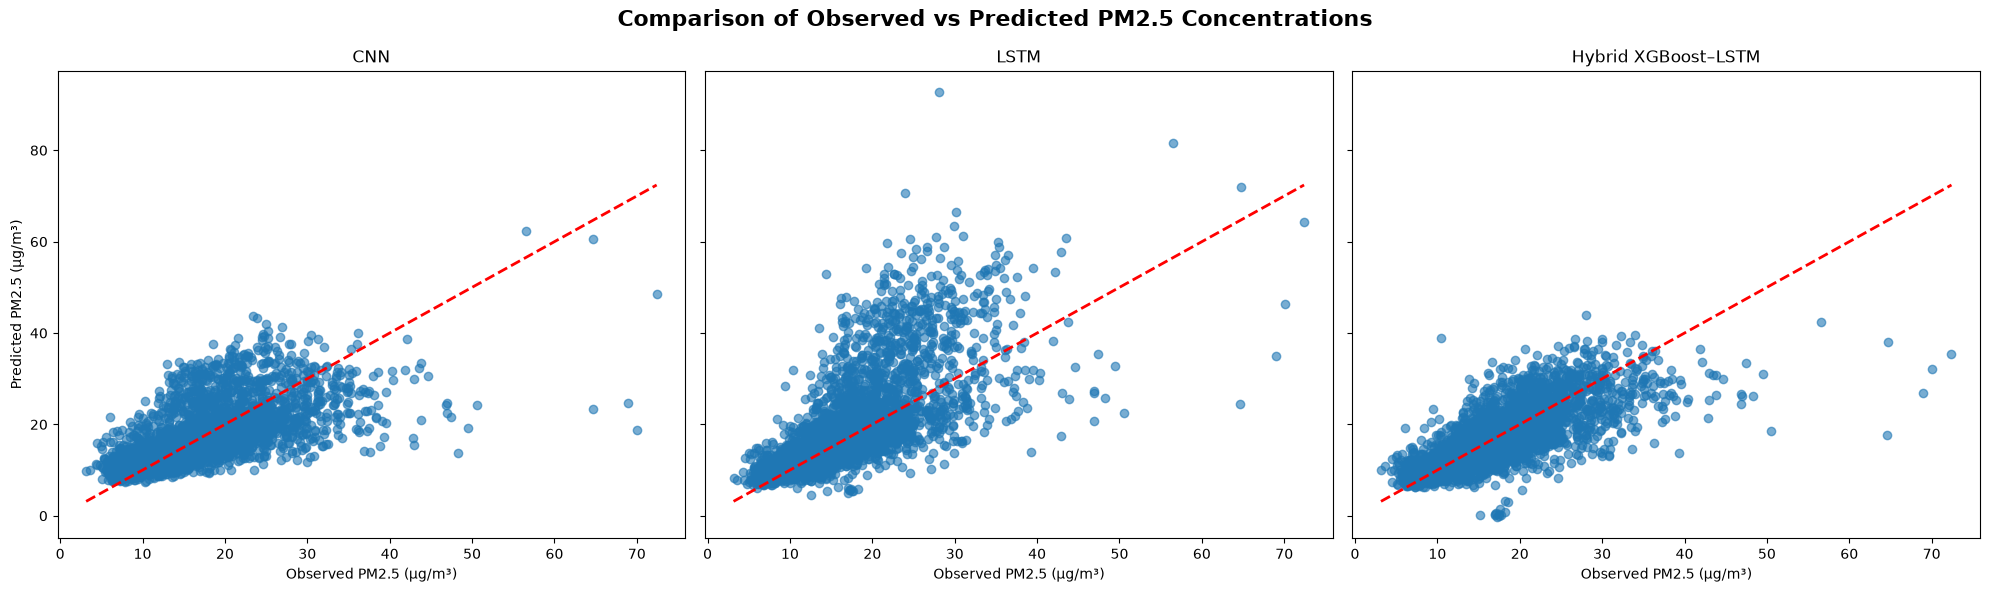

In [75]:
# Create a figure with three subplots.

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharex=True, sharey=True)

# ----------------------------------------------------
# CNN
# ----------------------------------------------------
axes[0].scatter(
    y_test_seq,
    cnn_predictions,
    alpha=0.6
)

axes[0].plot(
    [y_test_seq.min(), y_test_seq.max()],
    [y_test_seq.min(), y_test_seq.max()],
    "r--",
    linewidth=2
)

axes[0].set_title("CNN")
axes[0].set_xlabel("Observed PM2.5 (µg/m³)")
axes[0].set_ylabel("Predicted PM2.5 (µg/m³)")

# ----------------------------------------------------
# LSTM
# ----------------------------------------------------
axes[1].scatter(
    y_test_seq,
    lstm_predictions,
    alpha=0.6
)

axes[1].plot(
    [y_test_seq.min(), y_test_seq.max()],
    [y_test_seq.min(), y_test_seq.max()],
    "r--",
    linewidth=2
)

axes[1].set_title("LSTM")
axes[1].set_xlabel("Observed PM2.5 (µg/m³)")

# ----------------------------------------------------
# Hybrid XGBoost–LSTM
# ----------------------------------------------------
axes[2].scatter(
    y_test_hybrid,
    hybrid_predictions,
    alpha=0.6
)

axes[2].plot(
    [y_test_hybrid.min(), y_test_hybrid.max()],
    [y_test_hybrid.min(), y_test_hybrid.max()],
    "r--",
    linewidth=2
)

axes[2].set_title("Hybrid XGBoost–LSTM")
axes[2].set_xlabel("Observed PM2.5 (µg/m³)")

# ----------------------------------------------------
# Figure title
# ----------------------------------------------------
fig.suptitle(
    "Comparison of Observed vs Predicted PM2.5 Concentrations",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("ObservedVsPredicted.png")
plt.show()

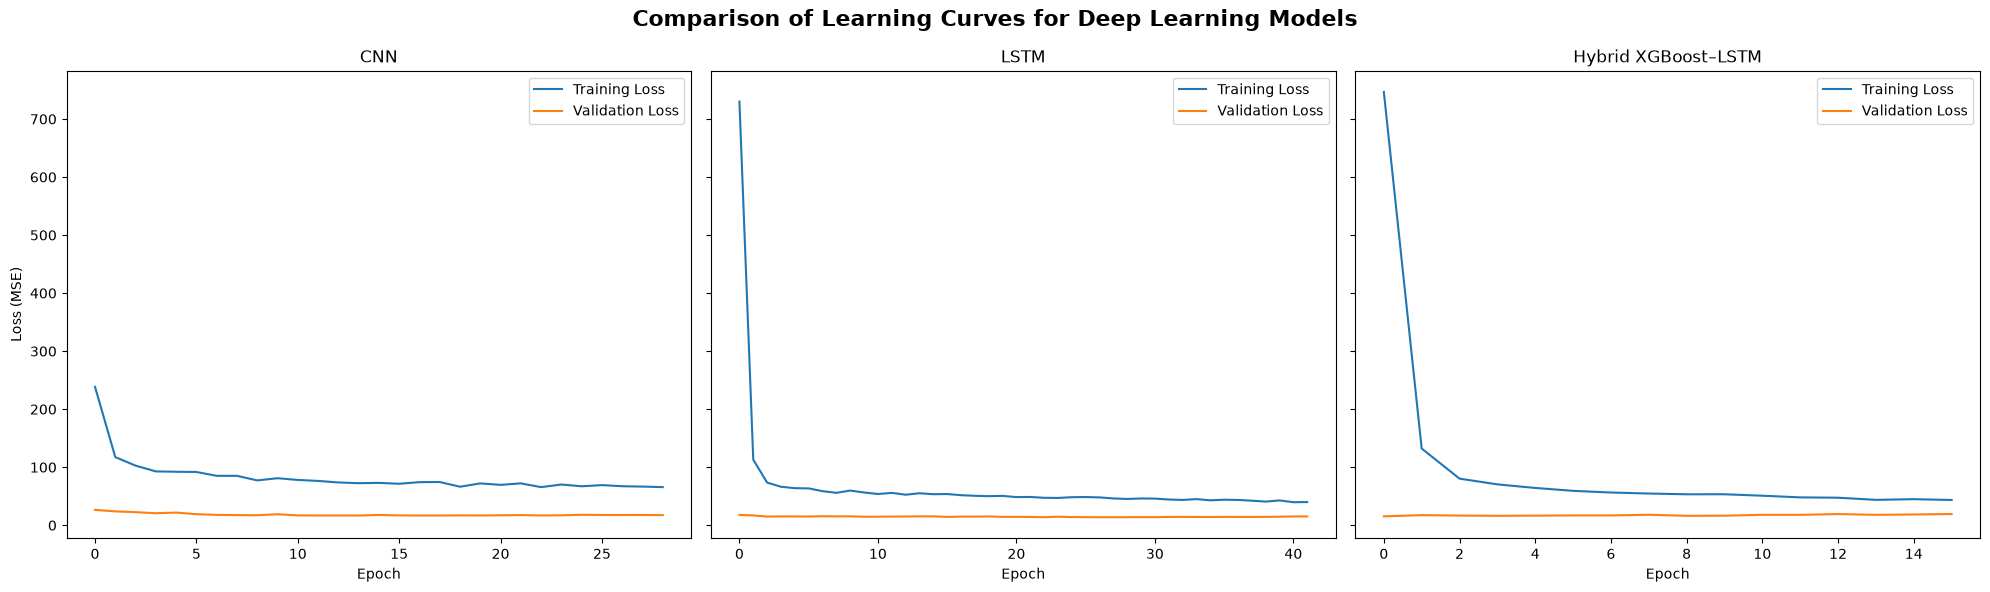

In [77]:
# Create a figure with three subplots.

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)

# ----------------------------------------------------
# CNN Learning Curve
# ----------------------------------------------------
axes[0].plot(
    history_cnn.history["loss"],
    label="Training Loss"
)

axes[0].plot(
    history_cnn.history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("CNN")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss (MSE)")
axes[0].legend()

# ----------------------------------------------------
# LSTM Learning Curve
# ----------------------------------------------------
axes[1].plot(
    history_lstm.history["loss"],
    label="Training Loss"
)

axes[1].plot(
    history_lstm.history["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("LSTM")
axes[1].set_xlabel("Epoch")
axes[1].legend()

# ----------------------------------------------------
# Hybrid XGBoost–LSTM Learning Curve
# ----------------------------------------------------
axes[2].plot(
    history_hybrid.history["loss"],
    label="Training Loss"
)

axes[2].plot(
    history_hybrid.history["val_loss"],
    label="Validation Loss"
)

axes[2].set_title("Hybrid XGBoost–LSTM")
axes[2].set_xlabel("Epoch")
axes[2].legend()

# ----------------------------------------------------
# Overall Title
# ----------------------------------------------------
fig.suptitle(
    "Comparison of Learning Curves for Deep Learning Models",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("loss.png")
plt.show()

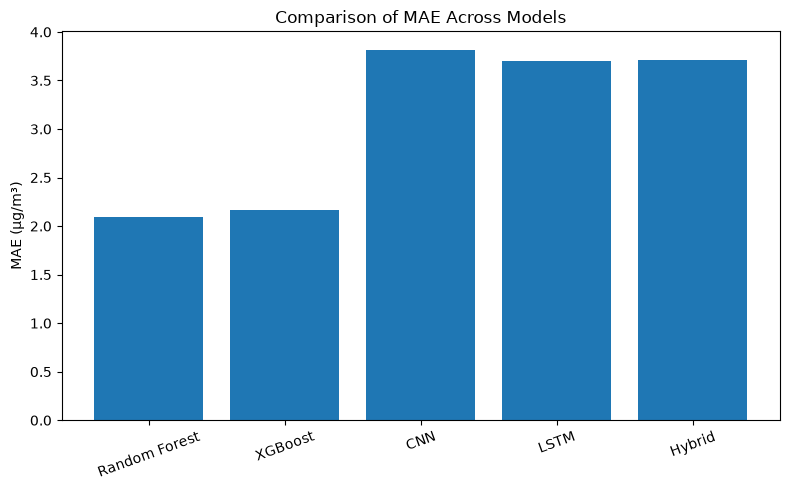

In [79]:
# MAE Variables
rf_mae = 2.0947
xgb_mae = 2.1662
cnn_mae = 3.8156
lstm_mae = 3.6968
hybrid_mae = 3.7146

models = [
    "Random Forest",
    "XGBoost",
    "CNN",
    "LSTM",
    "Hybrid"
]

mae = [
    rf_mae,
    xgb_mae,
    cnn_mae,
    lstm_mae,
    hybrid_mae
]

plt.figure(figsize=(8,5))

plt.bar(models, mae)

plt.ylabel("MAE (µg/m³)")
plt.title("Comparison of MAE Across Models")

plt.xticks(rotation=20)

plt.tight_layout()
plt.savefig("summary_evaluation.png")
plt.show()